# F03.03b · El atajo de la grabación: ¿queda señal preictal cuando se le quita al modelo la pista de la sesión?

> 🧭 **En 30 segundos**
> - **Para qué:** F03.03 y F03.04 vieron que, con 💤 de la **misma sesión** que las ⏳, la nota se cae (la red, incluso **por debajo del azar**). El modelo reconoce **la grabación** ("esta sesión es de las que tienen crisis") en vez de **la cercanía de la crisis**. Aquí se mide ese atajo, se busca su causa y se prueban varias formas de quitárselo (entrenar solo con 💤 de la misma sesión, solo con un montaje), con XGBoost (rápido) antes de gastar horas de GPU en redes.
> - **Entra:** las ventanas y características de contexto de **F03.03** (no se vuelve a leer la señal), el inventario de crisis de **F01.01** y las puntuaciones guardadas de F03.03 y F03.04 → **Sale:** el diagnóstico, la nota de cada combinación con el **control estricto** y la **decisión para la red**, que F03.04 y los siguientes leen solos.
> - **Idea clave:** la nota que manda aquí no es la de siempre, sino la del **control estricto**: las ⏳ frente a 💤 de **su misma sesión** y de **antes de toda crisis** de esa sesión. Ahí no hay pista de grabación ni de postictal: si un modelo acierta, es porque ve algo antes de la crisis.

> 📍 **Dónde estamos: Fase 3 · entre F03.03 y F03.04 (F03.03b).** F03.03 decidió qué recibe la red mirando la nota con todas las 💤. Este notebook revisa esa decisión con el control estricto. Si existe su `configuracion.json`, **F03.04 y `tfm_comun/red/preparacion.py` (F03.05-F03.08) usan su decisión** en lugar de la de F03.03.

> 🔄 **Es dinámico.** Las cifras, la decisión y las conclusiones salen de los datos al ejecutarlo.

> 🔒 **Regla de oro de la Fase 3: aquí no se mira 🟢 eval.** Todo se decide con 🟡 dev.

| Fase del TFM | | Estado |
|---|---|---|
| Fase 1 | Exploración de datos | ✅ terminada |
| Fase 2 | Preprocesado y ventanas | ✅ terminada |
| **Fase 3** | **Modelo de predicción (⏳ preictal frente a 💤 interictal)** | 👉 **en curso** (la fase de este notebook) |
| Fase 4 | Clasificación de tipos de crisis | pendiente |
| Fase 5 | Explicabilidad (XAI) | pendiente |
| Fase 6 | Memoria | pendiente |
| Fase 7 | Revisión y defensa | pendiente |

## 🧩 La idea, en sencillo

Imagina un detector de mentiras que "acierta" porque a los sospechosos los interrogan en una sala y a los inocentes en otra: no detecta mentiras, detecta **la sala**. En TUSZ pasa algo parecido:

1. **La sala (la sesión).** Las ⏳ salen siempre de sesiones con crisis; casi todas las 💤, de **otras** sesiones (otro día, otro equipo, otro montaje, monitorización larga frente a EEG de rutina). Un modelo puede aprender "esta grabación es de las de crisis".
2. **El después (el postictal).** Dentro de una sesión con crisis, muchas 💤 son de **después** de una crisis. Las 💤 ya dejan fuera 5 min tras cada crisis (`tfm_comun/prediccion/umbrales.py`), pero el EEG puede seguir alterado más tiempo. Un modelo que aprendió "alterado = ⏳" ordena esas 💤 por encima de las ⏳: la AUC sale **por debajo del azar**, justo lo que vio F03.04.

| Pregunta | Dónde se responde |
|---|---|
| ¿Se puede reconocer, solo con 💤, si una sesión es "de las que tienen crisis"? ¿Va el montaje con las crisis? | §5 |
| ¿Las 💤 de después de una crisis explican la caída por debajo del azar? | §6 |
| ¿Deja el montaje una firma (canales vacíos)? ¿Cambia la nota comparando solo ventanas del mismo montaje? | §6b |
| ¿Se recupera la nota quitando la pista al entrenar (muestreo por sesión, un solo montaje)? | §7-§8 |
| ¿Queda señal preictal de verdad? ¿Qué recibe la red? | §9 (recuadro dorado) |

### Los arreglos que se prueban

| Arreglo | Qué hace | Qué pista quita |
|---|---|---|
| **Muestreo `misma_sesion`** | Al **entrenar**, solo 💤 de las sesiones donde su paciente tiene ⏳ | "esta grabación es de las de crisis": dentro de cada sesión hay de las dos clases |
| **Muestreo `misma_sesion_antes`** | Además, solo 💤 de **antes** de toda crisis de su sesión | también el postictal |
| **Montaje `01_tcp_ar`** | Al **entrenar**, solo ficheros con el montaje original más frecuente | el montaje: en 🔵 train va con las crisis y en 🟡 dev no |
| **Normalización `por_paciente_reserva`** | Cada paciente calibrado con sus primeras 💤 (la limpia de F03.03) | las diferencias de nivel entre pacientes |

Se combinan con el contexto (4 s y el mejor de F03.03) y se comparan con la línea base (4 s, sin normalizar, todas las 💤, todos los montajes), **siempre con las mismas ventanas: las de F03.03**. Los arreglos solo cambian con qué se **entrena**; la nota se mide siempre igual.

> 📝 **Por qué no se prueba calibrar cada sesión (`por_sesion_reserva`).** En la primera ejecución (2026-11-19) se apartó la reserva de cada sesión para todas las combinaciones y se perdió el **35 % de las ⏳**: las 💤 de 🔵 train son una muestra equilibrada repartida entre muchas sesiones y la mayoría no llegan al mínimo para calibrarse. Con los paquetes actuales no es viable; queda en `tfm_comun` para cuando F02.04 saque más 💤 de cada sesión.

### 📖 Diccionario rápido

| Término | Qué significa, en sencillo |
|---|---|
| **Sesión** | Un día de grabación de un paciente (`aaaaaajy_s003`). Puede tener varios ficheros (`_t000`, `_t001`...), que se suponen en orden de tiempo |
| **Atajo** (*shortcut*) | Una pista que permite acertar en los datos sin aprender lo que se quería (aquí: reconocer la grabación) |
| **Control estricto** | Las ⏳ frente a 💤 de su **misma sesión** y de **antes** de toda crisis de la sesión: sin pista de grabación ni de postictal |
| **Postictal** | El rato después de una crisis, con el EEG todavía alterado |
| **Muestreo** | Qué 💤 se usan **al entrenar** (la nota siempre se mide con las mismas ventanas de 🟡 dev) |
| **Montaje original** | Cómo estaban referenciados los electrodos en el EDF (`01_tcp_ar`, `02_tcp_le`, `03_tcp_ar_a`). F02 lo pasa todo a TCP, pero puede dejar huella: `03_tcp_ar_a` no tiene los electrodos de oreja (A1/A2) |
| **AUC-ROC** | La nota: 0,5 = azar, 1 = perfecto (F03.02 §5) |

## 0. Los parámetros

> 🎯 **Qué hacemos:** elegir el conjunto.

`CONJUNTO` se fija en un solo sitio para toda la Fase 3: `tfm_comun/prediccion/estudio.py` (`CONJUNTO_ESTUDIO`). Aquí se deja en `None`.

*(La celda lleva la etiqueta `parameters` para poder lanzarla con papermill.)*

In [1]:
CONJUNTO = None   # None = el de tfm_comun/prediccion/estudio.py (el mismo en toda la Fase 3)

## 1. Librerías

> 🎯 **Qué hacemos:** comprobar que están instaladas (las mismas que F03.03) e importar lo necesario.

In [2]:
# Requisitos: se comprueba (e instala si falta) lo que necesita el notebook ANTES de importar nada más
import sys
from pathlib import Path
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'tfm_comun').is_dir())))
from tfm_comun.entorno.requisitos import comprobar_requisitos, REQUISITOS_FASE_03_CONTEXTO
disponibles = comprobar_requisitos(REQUISITOS_FASE_03_CONTEXTO)

,estado,versión,para qué
librería,,,
numpy,✅,2.5.4,cálculo con matrices
pandas,✅,3.0.6,tablas
matplotlib,✅,3.11.2,figuras
scipy,✅,1.18.1,espectro de cada ventana (Welch)
scikit-learn,✅,1.9.1,"regresión logística, AUROC y curvas ROC"
xgboost,✅,3.4.1,XGBoost: árboles de decisión encadenados
joblib,✅,1.6.0,guardar los modelos entrenados
tqdm,✅,4.70.1,barra de progreso al calcular las características


Todo lo necesario está instalado.


In [3]:
# 1) Recarga automática de tfm_comun (sin reiniciar el kernel)
%load_ext autoreload
%autoreload 2
for modulo in [m for m in list(sys.modules) if m == 'tfm_comun' or m.startswith('tfm_comun.')]:
    del sys.modules[modulo]

# 2) Librerías de siempre
import json
from functools import partial
import re
import time

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
import sklearn
import xgboost
from tqdm.auto import tqdm
from IPython.display import display, Markdown

# 3) tfm_comun: rutas, paquetes, características y contexto (lo mismo que F03.03)
from tfm_comun.entorno.rutas import RUTA_OUTPUTS_FASE_03, RUTA_SENALES, carpeta_resultados
from tfm_comun.entorno.versiones import mostrar_versiones
from tfm_comun.entorno.configuracion import leer_configuracion
from tfm_comun.senal.montaje import CANALES_TCP
from tfm_comun.red.paquetes import cargar_paquete
from tfm_comun.prediccion.caracteristicas import nombres_caracteristicas
from tfm_comun.prediccion.almacen_caracteristicas import caracteristicas_al_dia, guardar_caracteristicas, cargar_caracteristicas
from tfm_comun.prediccion.contextos.duracion import ventanas_por_contexto
from tfm_comun.prediccion.contextos.disponibilidad import con_contexto_completo, inicios_necesarios, clave
from tfm_comun.prediccion.contextos.calculo import caracteristicas_de_inicios
from tfm_comun.prediccion.contextos.indices import cubo_contexto
from tfm_comun.prediccion.contextos.resumen import resumir_contexto

# 4) tfm_comun: el atajo de la grabación y la normalización (nuevo en F03.03b)
from tfm_comun.prediccion.atajo_grabacion import (MUESTREOS, MONTAJES_ENTRENAMIENTO, CONTROL_ESTRICTO, posicion_respecto_crisis,
                                                  controles_estrictos, mascara_muestreo, mascara_montaje, montaje_de_ficheros,
                                                  NOMBRE_CARPETA_03B)
from tfm_comun.prediccion.normalizacion_paciente import ventanas_del_estudio, normalizar_con_reserva, sesiones_de

# 5) tfm_comun: modelos y evaluación
from tfm_comun.prediccion.validacion import rondas_validacion
from tfm_comun.prediccion.linea_base import NOMBRES_MODELO, entrenar, puntuar
from tfm_comun.prediccion.evaluacion.auroc_global import auroc_con_intervalo, diferencia_auroc_con_intervalo
from tfm_comun.prediccion.evaluacion.auroc_paciente import auroc_dentro_paciente, auroc_dentro_paciente_con_intervalo
from tfm_comun.prediccion.evaluacion.lectura import lectura_diferencia

# 6) tfm_comun: cómo se enseñan las cosas
from tfm_comun.visual.iconos import con_icono
from tfm_comun.visual.colores import COLORES_PERIODO, COLORES_ESQUEMA
from tfm_comun.visual.numeros import numero_legible, decimal, con_intervalo, con_signo
from tfm_comun.visual.tablas import con_separadores, mostrar_destacado
from tfm_comun.visual.ficheros import mostrar_fichero
from tfm_comun.visual.tipografia import ESTILO_TIMES

# 7) Versiones y conjunto
versiones_usadas = mostrar_versiones(np, pd, matplotlib, scipy, sklearn, xgboost)
from tfm_comun.prediccion.estudio import conjunto_del_estudio
CONJUNTO = conjunto_del_estudio(CONJUNTO)

Python      3.14.0
numpy       2.5.4
pandas      3.0.6
matplotlib  3.11.2
scipy       1.18.1
sklearn     1.9.1
xgboost     3.4.1


✅ **Qué deberías ver:** la tabla de librerías con ✅ y sus versiones.

## 2. Configuración

> 🎯 **Qué hacemos:** leer lo que dejaron F03.01, F03.02 y F03.03 y fijar los "botones".
>
> 🤔 **Por qué:** el modelo y sus hiperparámetros son **los de F03.03** (XGBoost), y las ventanas, las suyas: así lo único que cambia es la pista que se quita.

| Parámetro | Valor | Qué controla |
|---|---|---|
| `CONTEXTOS` | 4 s y el mejor de F03.03 | Con qué contexto se prueba cada arreglo |
| `NORMALIZACIONES` | `ninguna`, `por_paciente_reserva` | Cómo se compara cada ventana con lo normal en su paciente (las dos de F03.03 sin fuga) |
| `MUESTREOS` | `todas`, `misma_sesion`, `misma_sesion_antes` | Qué 💤 se usan **al entrenar** |
| `MONTAJES` | `todos`, `01_tcp_ar` | Con qué montajes originales se **entrena** |
| `MINIMO_INTERICTAL` | 2.000 | 💤 de entrenamiento por debajo de las cuales una combinación no puede ser la elegida (aprendería casi solo de ⏳) |
| `UMBRAL_ATAJO` | 0,6 | En §5: a partir de qué AUC se considera que la sesión "se reconoce" con claridad |
| `MINIMO_PACIENTES_CONTROL` | 8 | Pacientes con las dos clases por debajo de los cuales el control estricto no se considera fiable |
| `ESPECIFICIDAD`, `N_BOOTSTRAP`, `MEJORA_MINIMA` | 0,9 · 500 · 0,02 | Como en F03.03 |

In [4]:
NORMALIZACIONES = ['ninguna', 'por_paciente_reserva']   # por_sesion_reserva no es viable con los paquetes actuales (ver arriba)
LISTA_MUESTREOS = list(MUESTREOS)                     # 'todas', 'misma_sesion', 'misma_sesion_antes'
LISTA_MONTAJES = list(MONTAJES_ENTRENAMIENTO)         # 'todos', '01_tcp_ar'
MINIMO_INTERICTAL = 2000
UMBRAL_ATAJO = 0.6
MINIMO_PACIENTES_CONTROL = 8
ESPECIFICIDAD = 0.9
N_BOOTSTRAP = 500
MEJORA_MINIMA = 0.02

In [5]:
# 1) Carpeta de resultados y configuraciones anteriores (comprobando que son de este CONJUNTO)
RUTA_RESULTADOS, RUTA_FIGURAS = carpeta_resultados(f'fase_03/{CONJUNTO}/{NOMBRE_CARPETA_03B}')
leer_config = partial(leer_configuracion, conjunto=CONJUNTO)
config_01 = leer_config(RUTA_OUTPUTS_FASE_03 / CONJUNTO / '01_datos_red' / 'configuracion.json', 'F03.01 (fase_03/01_datos_red.ipynb)')
config_03 = leer_config(RUTA_OUTPUTS_FASE_03 / CONJUNTO / '03_contexto_y_paciente' / 'configuracion.json', 'F03.03 (fase_03/03_contexto_y_paciente.ipynb)')

# 2) Las cifras que mandan F03.01 y F03.03
SEMILLA = int(config_01['semilla'])
VENTANA_S = config_01['ventana_s']
MUESTRAS = int(config_01['muestras_por_ventana'])
FS = MUESTRAS / VENTANA_S
SPLITS = [s for s in ['train', 'dev'] if s in config_01['paquetes']]          # 🟢 eval NO
K_MAX = ventanas_por_contexto(max(config_03['contextos_s']), VENTANA_S)       # las mismas filas que F03.03
RESERVA = config_03.get('reserva_calibracion')
assert RESERVA, '🔴 El configuracion.json de F03.03 no tiene reserva_calibracion: vuelve a ejecutar F03.03.'
CONTEXTOS = sorted({min(config_03['contextos_s']), int(config_03['mejor']['contexto_s'])})
MODELO = 'xgboost'
VARIANTE, HIPERPARAMETROS = config_03['modelos'][MODELO]['variante'], config_03['modelos'][MODELO]['hiperparametros']
NOMBRES = nombres_caracteristicas(CANALES_TCP)

# 3) Resumen
print(f'Conjunto: {CONJUNTO} · modelo: {NOMBRES_MODELO[MODELO]} ({VARIANTE}, {HIPERPARAMETROS}) · contextos: {", ".join(f"{c} s" for c in CONTEXTOS)}')
print(f'Decisión de F03.03: {config_03["decision_red"]["texto"]} ({config_03["decision_red"]["contexto_s"]} s, {config_03["decision_red"]["normalizacion"]}) · '
      f'su control de sesión: {config_03.get("control_sesion", {}).get("veredicto", "—")}')

Conjunto: general · modelo: XGBoost (mismo_peso_paciente, {'max_depth': 5, 'n_estimators': 300, 'learning_rate': 0.05}) · contextos: 4 s, 60 s
Decisión de F03.03: La red recibirá 60 s de contexto y cada paciente normalizado frente a sí mismo (🟡 robustez por confirmar) (60 s, por_paciente_reserva) · su control de sesión: 🔴 Se cae: reconocía la grabación


## 3. Las ventanas y dónde está cada 💤 respecto a las crisis

> 🎯 **Qué hacemos:** (1) tomar **exactamente las ventanas de F03.03** (contexto completo, sin la reserva de calibración por paciente); (2) situar cada 💤 respecto a las crisis de su sesión con el inventario de F01.01 (`crisis.csv`); (3) apuntar el montaje original de cada fichero (`edfs.csv`).
>
> 🤔 **Por qué:** para comparar arreglos hacen falta las mismas ventanas en todos, y las de F03.03 son con las que se midió todo lo anterior. Y para separar "antes" de "después" de una crisis hay que saber cuándo empezó y acabó cada una, también en los ficheros sin ventanas ⏳.

Cada 💤 cae en uno de tres grupos:

| Grupo | Qué es |
|---|---|
| **otra sesión** | de una sesión sin ⏳ de su paciente (la pista de la grabación) |
| **misma sesión, antes** | de la misma sesión que sus ⏳, y sin ninguna crisis antes en la sesión |
| **misma sesión, después** | de la misma sesión que sus ⏳, pero después de alguna crisis (posible postictal) |

In [6]:
# 1) Las filas de F03.03: 🔵 train + 🟡 dev con el contexto completo más largo
todas = pd.concat([cargar_paquete(CONJUNTO, s)[1] for s in SPLITS], ignore_index=True)
completo = con_contexto_completo(todas, K_MAX, MUESTRAS)
filas_todas = todas[completo].reset_index(drop=True)

# 2) Ventanas que se usan: las de F03.03 (sin la reserva de calibración por paciente). Las mismas para todas las combinaciones
reserva_de, usar_todas = {}, None
for normalizacion in NORMALIZACIONES:
    reservada_n, usar_n, grupos_n = ventanas_del_estudio(filas_todas, FS, VENTANA_S, RESERVA, normalizacion, reserva_por_sesion=False)
    reserva_de[normalizacion] = (reservada_n, grupos_n)
    usar_todas = usar_n if usar_todas is None else usar_todas & usar_n
filas = filas_todas[usar_todas].reset_index(drop=True)
y = filas.etiqueta.to_numpy()
pacientes = filas.patient.to_numpy()
ficheros = filas.file.astype(str).to_numpy()
sesiones = sesiones_de(filas)
rondas = rondas_validacion(filas)
validar = np.any([v for _, _, v in rondas], axis=0)
for nombre, entrena, valida in rondas:
    assert not set(pacientes[entrena]) & set(pacientes[valida]), f'🔴 {nombre}: pacientes en entrenamiento y validación a la vez.'

# 3) Dónde está cada ventana respecto a las crisis de su sesión (inventario de F01.01)
posicion = posicion_respecto_crisis(filas, FS)
antes = posicion.antes_de_toda_crisis.to_numpy()
con_preictal = set(zip(pacientes[y == 1], sesiones[y == 1]))                      # (paciente, sesión) con alguna ⏳
misma_sesion = np.fromiter(((p, s) in con_preictal for p, s in zip(pacientes, sesiones)), dtype=bool, count=len(filas))
grupo_interictal = np.where(y == 1, '⏳ preictal', np.where(~misma_sesion, '💤 otra sesión',
                                                            np.where(antes, '💤 misma sesión, antes', '💤 misma sesión, después')))
montaje = montaje_de_ficheros(ficheros)                                           # montaje original de cada ventana (F01.01)

# 4) Tabla: cuántas ventanas de cada grupo por partición
tabla_grupos = pd.crosstab(pd.Series(grupo_interictal, name='qué ventana'), pd.Series([con_icono(s) for s in filas.split], name='split'))
tabla_grupos.loc['total'] = tabla_grupos.sum()
display(con_separadores(tabla_grupos, decimales=0))
print(f'Se usan {numero_legible(len(filas))} de {numero_legible(len(filas_todas))} ventanas con contexto completo · '
      f'⏳ que se quedan: {numero_legible(int(y.sum()))} de {numero_legible(int((filas_todas.etiqueta == 1).sum()))}')
print('✅ Las mismas ventanas que F03.03.' if len(filas) == config_03.get('ventanas_estudiadas') else
      f'🔴 F03.03 usó {numero_legible(config_03.get("ventanas_estudiadas", 0))} ventanas y aquí hay {numero_legible(len(filas))}: ¿se volvió a ejecutar F03.01 después?')
en_train = filas.en_entrenamiento.to_numpy(dtype=bool)
print('💤 de 🔵 train con las que puede aprender cada muestreo: '
      + ' · '.join(f'{mu}: {numero_legible(int((mascara_muestreo(en_train, y, pacientes, ficheros, antes, mu) & (y == 0)).sum()))}' for mu in LISTA_MUESTREOS))

split,🔵 train,🟡 dev
qué ventana,,
⏳ preictal,13.329,7.519
"💤 misma sesión, antes",443,1.609
"💤 misma sesión, después",4.865,5.703
💤 otra sesión,4.731,33.998
total,23.368,48.829


Se usan 72.197 de 75.839 ventanas con contexto completo · ⏳ que se quedan: 20.848 de 21.123
✅ Las mismas ventanas que F03.03.
💤 de 🔵 train con las que puede aprender cada muestreo: todas: 10.039 · misma_sesion: 5.308 · misma_sesion_antes: 443


👀 **Cómo leer la tabla.** Cuántas ventanas hay de cada grupo en 🔵 train y 🟡 dev: las ⏳ y las 💤 según su sesión y su momento. Debajo, cuántas se apartan respecto a F03.03.

✅ **Qué deberías ver:** las mismas ventanas que F03.03 (✅) y, en 🟡 dev, muchas más 💤 de **otra sesión** que de la misma: es el origen del atajo. Debajo, con cuántas 💤 de 🔵 train puede aprender cada muestreo: si un muestreo se queda con menos de `MINIMO_INTERICTAL`, sus combinaciones no pueden ser la elegida en §8 (aprenderían casi solo de ⏳).

## 4. Las características: las mismas que F03.03

> 🎯 **Qué hacemos:** leer del almacén las características de cada ventana de 4 s (las que calculó F03.03; si están al día no se vuelve a leer la señal) y resumir el contexto (media, variación y cambio) para cada duración.

In [7]:
# 1) Las ventanas de 4 s que hacen falta (las mismas claves que F03.03: así se reutiliza su almacén)
inicio = time.time()
necesarias = inicios_necesarios(filas_todas, K_MAX, MUESTRAS)
claves = clave(necesarias.ruta, necesarias.inicio)
nombre_almacen = f'contexto_{CONJUNTO}'
if caracteristicas_al_dia(nombre_almacen, 'train_dev', claves, len(NOMBRES)):
    estado = 'ya estaba al día (el de F03.03)'
else:
    estado = 'calculado'
    valores = caracteristicas_de_inicios(necesarias, RUTA_SENALES, FS, MUESTRAS,
                                         progreso=lambda it, total: tqdm(it, total=total, desc='tramos de F02.02 leídos'))
    guardar_caracteristicas(nombre_almacen, 'train_dev', claves, valores)
valores, claves_guardadas = cargar_caracteristicas(nombre_almacen, 'train_dev')

# 2) El contexto de cada fila, resumido (4 s = la ventana sola)
X_contexto = {}
for contexto in CONTEXTOS:
    k = ventanas_por_contexto(contexto, VENTANA_S)
    cubo = cubo_contexto(filas, k, MUESTRAS, claves_guardadas, valores)
    X_contexto[contexto] = cubo[:, -1, :] if k == 1 else resumir_contexto(cubo)
print(f'Almacén {nombre_almacen}: {estado} · ' + ' · '.join(f'{c} s → {X_contexto[c].shape[1]} números' for c in CONTEXTOS)
      + f' · {numero_legible(round((time.time() - inicio) / 60, 1))} min')

Almacén contexto_general: ya estaba al día (el de F03.03) · 4 s → 110 números · 60 s → 330 números · 0,1 min


## 5. Diagnóstico 1: ¿se reconoce la sesión con crisis solo con 💤?

> 🎯 **Qué hacemos:** entrenar XGBoost **solo con 💤** de 🔵 train para distinguir "💤 de una sesión con crisis" de "💤 de una sesión sin crisis", y medirlo con las 💤 de 🟡 dev (pacientes nuevos). Se da la AUC global y la AUC **dentro del paciente** (solo pacientes con sesiones de los dos tipos).
>
> 🤔 **Por qué:** ninguna de esas ventanas está cerca de una crisis. Si aun así el modelo distingue las sesiones, **la pista existe**: hay algo en la grabación (equipo, montaje, tipo de registro) que la delata. Si la AUC dentro del paciente también es alta, ni siquiera hace falta saber quién es el paciente.

Además se mira una causa concreta y barata de comprobar: el **montaje original** de cada fichero (`01_tcp_ar`, `02_tcp_le`...), del inventario de F01.01.

In [8]:
# 1) Solo 💤, con su etiqueta "sesión con crisis" (contexto de 4 s, sin normalizar)
X4 = X_contexto[min(CONTEXTOS)]
sesion_con_crisis = posicion.sesion_con_crisis.to_numpy().astype(int)
interictal = y == 0
entrena_s = interictal & filas.en_entrenamiento.to_numpy(dtype=bool)
valida_s = interictal & validar
clases_ok = len(set(sesion_con_crisis[entrena_s])) == 2 and len(set(sesion_con_crisis[valida_s])) == 2

# 2) Entrenar y medir
if clases_ok:
    modelo_sesion = entrenar(MODELO, HIPERPARAMETROS, X4[entrena_s], sesion_con_crisis[entrena_s], pacientes[entrena_s], VARIANTE, SEMILLA)
    p_sesion = puntuar(modelo_sesion, X4[valida_s])
    auc_s = auroc_con_intervalo(sesion_con_crisis[valida_s], p_sesion, pacientes[valida_s], n_bootstrap=N_BOOTSTRAP, semilla=SEMILLA)
    pac_dos = [p for p in set(pacientes[valida_s]) if len(set(sesion_con_crisis[valida_s][pacientes[valida_s] == p])) == 2]
    auc_s_dentro = (auroc_dentro_paciente_con_intervalo(sesion_con_crisis[valida_s], p_sesion, pacientes[valida_s], n_bootstrap=N_BOOTSTRAP, semilla=SEMILLA)
                    if len(pac_dos) >= 2 else (np.nan, np.nan, np.nan))
else:
    auc_s, auc_s_dentro, pac_dos = (np.nan, np.nan, np.nan), (np.nan, np.nan, np.nan), []

# 3) El montaje original (de §3): ¿cambia entre sesiones con y sin crisis?
tabla_montaje = (pd.crosstab([pd.Series([con_icono(s) for s in filas.split], name='split'),
                              pd.Series(np.where(y == 1, '⏳ preictal', np.where(sesion_con_crisis == 1, '💤 sesión con crisis', '💤 sesión sin crisis')), name='ventanas')],
                             pd.Series(montaje, name='montaje original'), normalize='index') * 100)

# 4) Veredicto del diagnóstico
if not clases_ok:
    veredicto_atajo = ('— No se puede medir', 'En train o en dev no hay 💤 de los dos tipos de sesión.')
elif auc_s[1] > 0.5 and auc_s[0] >= UMBRAL_ATAJO:
    veredicto_atajo = ('🔴 El atajo existe: la sesión con crisis se reconoce',
                       f'Solo con 💤, el modelo distingue las sesiones con crisis de las sin crisis con <b>AUC {con_intervalo(*auc_s)}</b>'
                       + (f' (dentro del paciente: {con_intervalo(*auc_s_dentro)}, {len(pac_dos)} pacientes)' if not np.isnan(auc_s_dentro[0]) else '')
                       + '. Cualquier modelo entrenado con todas las 💤 puede usar esa pista.')
elif auc_s[1] > 0.5:
    veredicto_atajo = ('🟡 El atajo existe, pero es débil',
                       f'Solo con 💤, AUC {con_intervalo(*auc_s)}: la sesión se reconoce algo, menos que el umbral de {decimal(UMBRAL_ATAJO)}.')
else:
    veredicto_atajo = ('✅ La sesión no se reconoce solo con 💤',
                       f'AUC {con_intervalo(*auc_s)}: con estas características la grabación no se delata por sí sola. '
                       'Si el control de sesión cae, la causa más probable es el postictal (§6).')

# 5) Mostrarlo
mostrar_destacado(f'Diagnóstico 1 · {veredicto_atajo[0]}', veredicto_atajo[1],
                  '<b>Montaje original</b> (% de ventanas de cada fila con cada montaje):', con_separadores(tabla_montaje, decimales=1))

👀 **Cómo leer el recuadro.** Arriba, la nota del modelo que intenta adivinar, solo con 💤, si una sesión tiene crisis: 0,5 = no la reconoce; cuanto más alta, más se delata la grabación. Debajo, el montaje original: si las ⏳ y las 💤 de sesiones con crisis usan otro montaje que las 💤 de sesiones sin crisis, ya hay una pista concreta (aunque F02 lo pase todo a TCP, la referencia original puede dejar huella).

✅ **Qué deberías ver:** si sale 🔴, queda confirmado lo que vio F03.04: hay que entrenar sin esa pista (§7). Si sale ✅, la caída del control de sesión viene de otro sitio (mira §6).

## 6. Diagnóstico 2: ¿las 💤 de después de una crisis explican la caída?

> 🎯 **Qué hacemos:** volver a medir los modelos **ya entrenados** de F03.03 (línea base y mejor combinación) y, si existe, la red de F03.04, con los controles de sesión, separando las 💤 de la misma sesión en **antes** y **después** de una crisis. No se entrena nada.
>
> 🤔 **Por qué:** si con las 💤 de **después** la nota cae por debajo de 0,5 y con las de **antes** no, el problema es el postictal: el modelo aprendió "alterado = ⏳". Si cae en las dos, es la sesión.

In [9]:
# 1) Los controles, con las 💤 de antes y de después separadas
controles = controles_estrictos(validar, y, pacientes, ficheros, antes)

# 2) Las puntuaciones guardadas de F03.03 y F03.04 (por id de ventana: solo las que coinciden)
guardadas = {}
ruta_03 = RUTA_OUTPUTS_FASE_03 / CONJUNTO / '03_contexto_y_paciente' / 'puntuaciones_validacion.csv'
p03 = pd.read_csv(ruta_03).set_index('id_ventana')
guardadas['F03.03 · línea base (4 s)'] = filas.id_ventana.map(p03['puntuacion_linea_base_4s']).to_numpy(dtype=float)
guardadas[f'F03.03 · mejor ({config_03["mejor"]["contexto_s"]} s, {config_03["mejor"]["normalizacion"]})'] = filas.id_ventana.map(p03['puntuacion_mejor']).to_numpy(dtype=float)
ruta_04 = RUTA_OUTPUTS_FASE_03 / CONJUNTO / '04_red_prediccion' / 'puntuaciones_validacion.csv'
if ruta_04.exists():
    p04 = pd.read_csv(ruta_04).set_index('id_ventana')
    for columna in [c for c in p04.columns if c.startswith('puntuacion_red')][:1]:
        guardadas[f'F03.04 · {columna.replace("puntuacion_", "")}'] = filas.id_ventana.map(p04[columna]).to_numpy(dtype=float)

# 3) La AUC de cada modelo guardado en cada control
filas_diag = {}
for nombre_control, m in controles.items():
    fila = {'pacientes con las dos clases': len({p for p in set(pacientes[m]) if len(set(y[m & (pacientes == p)])) == 2}),
            '💤 interictal': int((y[m] == 0).sum())}
    for nombre_modelo, p in guardadas.items():
        mm = m & ~np.isnan(p)
        if (y[mm] == 0).sum() and (y[mm] == 1).sum():
            a, i_, s_ = auroc_con_intervalo(y[mm], p[mm], pacientes[mm], n_bootstrap=N_BOOTSTRAP, semilla=SEMILLA)
            fila[nombre_modelo] = f'{decimal(a)} [{decimal(i_)} – {decimal(s_)}]'
    filas_diag[nombre_control] = fila
diagnostico_postictal = pd.DataFrame(filas_diag).T
diagnostico_postictal.index.name = 'qué 💤 se usan'
display(Markdown('**AUC en dev de los modelos ya entrenados, según qué 💤 se usan** (las ⏳ son siempre las mismas)'))
display(diagnostico_postictal)

# 4) ¿A qué distancia de la crisis están las 💤 de "después" (en el mismo fichero)?
desde_min = posicion.segundos_desde_crisis.to_numpy() / 60
d = desde_min[validar & (y == 0) & misma_sesion & ~antes & ~np.isnan(desde_min)]
print(f'💤 de dev de la misma sesión y de después de una crisis: {numero_legible(int((validar & (y == 0) & misma_sesion & ~antes).sum()))} · '
      + (f'en el mismo fichero que la crisis: {numero_legible(len(d))}, a una mediana de {decimal(np.median(d), 1)} min del final de la crisis '
         f'(el 25 % a menos de {decimal(np.percentile(d, 25), 1)} min)' if len(d) else 'ninguna en el mismo fichero que la crisis'))

**AUC en dev de los modelos ya entrenados, según qué 💤 se usan** (las ⏳ son siempre las mismas)

,pacientes con las dos clases,💤 interictal,F03.03 · línea base (4 s),"F03.03 · mejor (60 s, por_paciente)",F03.04 · red_4s
qué 💤 se usan,,,,,
todas las 💤,28,41310,"0,46 [0,38 – 0,53]","0,58 [0,50 – 0,63]","0,43 [0,36 – 0,54]"
misma sesión,25,7312,"0,45 [0,37 – 0,55]","0,54 [0,46 – 0,59]","0,36 [0,30 – 0,48]"
"misma sesión, antes de la crisis",15,1609,"0,47 [0,35 – 0,59]","0,51 [0,38 – 0,62]","0,30 [0,22 – 0,46]"
"misma sesión, después de una crisis",23,5703,"0,45 [0,36 – 0,55]","0,54 [0,47 – 0,59]","0,38 [0,31 – 0,50]"
mismo fichero,18,1020,"0,37 [0,28 – 0,48]","0,43 [0,30 – 0,55]","0,30 [0,23 – 0,41]"


💤 de dev de la misma sesión y de después de una crisis: 5.703 · en el mismo fichero que la crisis: 1.097, a una mediana de 9,9 min del final de la crisis (el 25 % a menos de 7,5 min)


👀 **Cómo leer la tabla.** Una fila por control y una columna por modelo ya entrenado (AUC con su intervalo por paciente). La fila clave es la del **control estricto** (*misma sesión, antes de la crisis*) frente a *misma sesión, después de una crisis*.

✅ **Qué deberías ver:**
- Si *después* está **por debajo de 0,5** y *antes* no, el problema es el **postictal**.
- Si *antes* también cae al azar, el modelo **no predice** dentro de la sesión: lo que separaba era la sesión.
- Ojo con las filas con pocos pacientes: con menos de `MINIMO_PACIENTES_CONTROL`, la cifra es orientativa.

## 6b. Diagnóstico 3: ¿deja el montaje una firma?

> 🎯 **Qué hacemos:** (1) contar, en cada ventana, cuántos **canales vacíos** tiene (canales sin características: NaN), por montaje original y clase; (2) medir los modelos ya entrenados **dentro de cada montaje**: solo ⏳ y 💤 del mismo montaje.
>
> 🤔 **Por qué:** el montaje `03_tcp_ar_a` no tiene los electrodos de oreja (A1/A2). Al pasar a TCP (F02.02), los canales que los usan (`A1-T3` y `T4-A2`) quedan vacíos, así que cualquier modelo **reconoce el montaje** enseguida (XGBoost trata los NaN como un valor más). Eso **solo es un problema si el montaje va con la clase**: si en 🔵 train ese montaje tuviera más ⏳ que 💤 (o al revés), el modelo aprendería "canales vacíos = ⏳", y en 🟡 dev, con otro reparto, la nota caería. Por eso el veredicto no mira si hay canales vacíos (en `03_tcp_ar_a` los hay siempre), sino **si el % de ventanas con canales vacíos es distinto en ⏳ y en 💤**. F02.05 mide lo mismo en el conjunto general (variable `canales_a_cero`).

In [10]:
# 1) ¿Deja el montaje una firma? Canales vacíos (sin características) en la ventana actual
numeros_por_canal = X4.shape[1] // len(CANALES_TCP)
canales_vacios = np.isnan(X4).sum(axis=1) / numeros_por_canal
montaje_txt = pd.Series(montaje).astype(str).to_numpy()
firma = (pd.DataFrame({'split': [con_icono(s) for s in filas.split], 'montaje': montaje_txt, 'clase': np.where(y == 1, '⏳ preictal', '💤 interictal'),
                       'vacio': 100.0 * (canales_vacios > 0), 'n_vacios': canales_vacios})
         .groupby(['split', 'montaje', 'clase'])
         .agg(ventanas=('vacio', 'size'), con_algun_canal_vacio=('vacio', 'mean'), canales_vacios_media=('n_vacios', 'mean'))
         .rename(columns={'con_algun_canal_vacio': '% con algún canal vacío', 'canales_vacios_media': 'canales vacíos (media)'}))
por_montaje = pd.Series(100.0 * (canales_vacios > 0)).groupby(montaje_txt).mean()

# 2) La nota de los modelos ya entrenados (§6) dentro de cada montaje (con todas las 💤 de ese montaje)
filas_mont = {}
for nombre_modelo, p in guardadas.items():
    ok = validar & ~np.isnan(p)
    fila = {}
    for nombre_m in ['todos'] + sorted(set(montaje_txt[ok])):
        m = ok if nombre_m == 'todos' else ok & (montaje_txt == nombre_m)
        if (y[m] == 0).sum() and len(set(pacientes[m & (y == 1)])) >= 3:
            a, i_, s_ = auroc_con_intervalo(y[m], p[m], pacientes[m], n_bootstrap=N_BOOTSTRAP, semilla=SEMILLA)
            fila[nombre_m] = f'{decimal(a)} [{decimal(i_)} – {decimal(s_)}]'
        else:
            fila[nombre_m] = '— (menos de 3 pacientes con ⏳)'
    fila['dentro del montaje'] = decimal(auroc_dentro_paciente(y[ok], p[ok], montaje_txt[ok]))
    filas_mont[nombre_modelo] = fila
auc_por_montaje = pd.DataFrame(filas_mont).T
auc_por_montaje.index.name = 'modelo (ya entrenado)'

# 3) Veredicto: reconocer el montaje solo importa si el montaje va con la clase
DIFERENCIA_FIRMA_PP = 10   # puntos de diferencia entre ⏳ y 💤 en el % de ventanas con canales vacíos
reparto_vacio = (pd.DataFrame({'split': filas.split.to_numpy(), 'preictal': y == 1, 'vacio': canales_vacios > 0})
                 .groupby(['split', 'preictal']).vacio.mean().mul(100).unstack())
diferencia_vacio = (reparto_vacio[True] - reparto_vacio[False]).dropna()          # ⏳ menos 💤, en puntos
texto_reparto = '; '.join(f'{con_icono(s)}: {decimal(reparto_vacio.loc[s, True], 0)} % de las ⏳ y {decimal(reparto_vacio.loc[s, False], 0)} % de las 💤'
                          for s in diferencia_vacio.index)
if por_montaje.max() > 0 and diferencia_vacio.abs().max() > DIFERENCIA_FIRMA_PP:
    veredicto_montaje = ('🔴 El montaje deja una firma y va con la clase',
                         f'Las ventanas de <b>{por_montaje.idxmax()}</b> tienen canales vacíos y ese montaje no está repartido igual entre clases '
                         f'({texto_reparto}). Un modelo puede usar el montaje como pista. Aquí se prueba entrenar solo con <code>01_tcp_ar</code> (§7); '
                         'si se confirma, la solución de fondo es quitar <code>A1-T3</code> y <code>T4-A2</code> a todos los montajes en las características '
                         'o descartar los ficheros <code>03_tcp_ar_a</code>.')
elif por_montaje.max() > 0:
    veredicto_montaje = ('🟢 El montaje se reconoce, pero no va con la clase',
                         f'Las ventanas de <b>{por_montaje.idxmax()}</b> tienen canales vacíos, así que un modelo puede reconocer ese montaje, '
                         f'pero hay casi la misma proporción en ⏳ que en 💤 ({texto_reparto}): no le sirve para separarlas. '
                         'Coincide con F02.05 (<code>canales_a_cero</code> no separa). No hace falta tocar la Fase 2.')
else:
    veredicto_montaje = ('✅ Ningún canal vacío',
                         'Si el montaje deja huella, no es por canales vacíos (puede ser la referencia o el equipo): mira la tabla de AUC por montaje.')

# 4) Mostrarlo
mostrar_destacado(f'Diagnóstico 3 · {veredicto_montaje[0]}', veredicto_montaje[1],
                  '<b>Canales vacíos</b> por partición, montaje original y clase:', firma.round(1),
                  '<b>AUC en 🟡 dev de los modelos ya entrenados, dentro de cada montaje</b> (con todas las 💤 de ese montaje):', auc_por_montaje)

👀 **Cómo leer el recuadro.** Arriba, si algún montaje tiene muchas más ventanas con canales vacíos que los demás (una firma). En medio, la tabla por partición, montaje y clase. Abajo, la nota de los modelos ya entrenados comparando solo ventanas del mismo montaje; la última columna junta todos los montajes, pero comparando siempre dentro de cada uno.

✅ **Qué deberías ver:**
- Si sale 🔴 y en 🔵 train el montaje con canales vacíos tiene sobre todo ⏳ (o 💤 de sesiones con crisis), la firma explica por qué los modelos aprenden el montaje.
- Si la nota **dentro del montaje** sube respecto a la de *todos*, el montaje estaba restando: lo aprendido en train no vale en dev.

## 7. Los arreglos: entrenar sin la pista y medir con el control estricto

> 🎯 **Qué hacemos:** entrenar XGBoost (el de F03.03) con cada combinación de **contexto × normalización × muestreo × montaje de entrenamiento** y medir **todas** con las mismas ventanas de 🟡 dev (las de F03.03, todos los montajes): con todas las 💤, con las de la misma sesión y con el **control estricto**.
>
> 🤔 **Por qué:** el muestreo y el montaje solo cambian con qué se **entrena**; la nota se mide siempre igual. Así se ve si quitar la pista al entrenar mejora la nota **donde la pista no ayuda** (el control estricto), que es la única que le sirve a una app.

> 💡 Son pocas decenas de entrenamientos de XGBoost: unos minutos.

In [11]:
# 1) Las características de TODAS las filas con contexto completo: la normalización con reserva necesita las ventanas
#    reservadas (que no están en `filas`) para calibrar; después se queda con las que se usan
X_contexto_todas = {}
for contexto in CONTEXTOS:
    k = ventanas_por_contexto(contexto, VENTANA_S)
    cubo = cubo_contexto(filas_todas, k, MUESTRAS, claves_guardadas, valores)
    X_contexto_todas[contexto] = cubo[:, -1, :] if k == 1 else resumir_contexto(cubo)

def preparar(contexto, normalizacion):
    # las características de cada fila que se usa, con la normalización pedida
    X = X_contexto_todas[contexto]
    if normalizacion != 'ninguna':
        reservada_n, grupos_n = reserva_de[normalizacion]
        X = normalizar_con_reserva(X, grupos_n, reservada_n)
    return X[usar_todas]

# 2) Entrenar cada combinación y medirla en los tres controles
evaluar_en = {n: controles[n] for n in ['todas las 💤', 'misma sesión', CONTROL_ESTRICTO]}
puntuaciones, filas_res = {}, {}
inicio = time.time()
combinaciones = [(c, n, mu, mo) for c in CONTEXTOS for n in NORMALIZACIONES for mu in LISTA_MUESTREOS for mo in LISTA_MONTAJES]
for contexto, normalizacion, muestreo, montaje_e in tqdm(combinaciones, desc='combinaciones'):
    X = preparar(contexto, normalizacion)
    p = np.full(len(filas), np.nan)
    n_preictal, n_interictal = 0, 0
    for _, entrena, valida in rondas:
        entrena_m = mascara_montaje(mascara_muestreo(entrena, y, pacientes, ficheros, antes, muestreo), ficheros, montaje_e)
        n_preictal, n_interictal = n_preictal + int((y[entrena_m] == 1).sum()), n_interictal + int((y[entrena_m] == 0).sum())
        modelo = entrenar(MODELO, HIPERPARAMETROS, X[entrena_m], y[entrena_m], pacientes[entrena_m], VARIANTE, SEMILLA)
        p[valida] = puntuar(modelo, X[valida])
    puntuaciones[(contexto, normalizacion, muestreo, montaje_e)] = p
    fila = {'⏳ de entrenamiento': n_preictal, '💤 de entrenamiento': n_interictal,
            'elegible': 'sí' if n_interictal >= MINIMO_INTERICTAL else f'⚠️ no (menos de {numero_legible(MINIMO_INTERICTAL)} 💤)'}
    for nombre_control, m in evaluar_en.items():
        a, i_, s_ = auroc_con_intervalo(y[m], p[m], pacientes[m], n_bootstrap=N_BOOTSTRAP, semilla=SEMILLA)
        fila[f'AUC · {nombre_control}'] = a
        fila[f'IC · {nombre_control}'] = f'{decimal(i_)} – {decimal(s_)}'
        fila[f'_inf · {nombre_control}'], fila[f'_sup · {nombre_control}'] = i_, s_
    filas_res[(f'{contexto} s', normalizacion, muestreo, montaje_e)] = fila
resultados = pd.DataFrame(filas_res).T.infer_objects()
resultados.index.names = ['contexto', 'normalización', 'muestreo', 'montaje de entrenamiento']
columnas_ver = [c for c in resultados.columns if not c.startswith('_')]
display(con_separadores(resultados[columnas_ver], decimales=3))
print(f'{len(combinaciones)} combinaciones en {numero_legible(round((time.time() - inicio) / 60, 1))} min')

combinaciones:   0%|          | 0/24 [00:00<?, ?it/s]

24 combinaciones en 5,7 min


👀 **Cómo leer la tabla.** Una fila por combinación. Primero, con cuántas ⏳ y 💤 se entrenó y si la combinación puede ser la elegida (con muy pocas 💤 aprende casi solo de ⏳ y su nota no es de fiar). Después, por parejas: la AUC y su intervalo con **todas las 💤** (la nota de siempre), con las de la **misma sesión** y con el **control estricto** (*misma sesión, antes de la crisis*).

✅ **Qué deberías ver:** que la nota con todas las 💤 **baje** al quitar la pista (era en parte atajo) y que la del control estricto **se mantenga o suba**. La combinación buena es la que mejor aguanta en la última columna, no la que más saca en la primera.

C:\Users\Usuario\AppData\Local\Temp\ipykernel_42324\1540220508.py:22: UserWarning: Glyph 9888 (\N{WARNING SIGN}) missing from font(s) Times New Roman.
  fig.tight_layout()
C:\Users\Usuario\AppData\Local\Temp\ipykernel_42324\1540220508.py:22: UserWarning: Glyph 128164 (\N{SLEEPING SYMBOL}) missing from font(s) Times New Roman.
  fig.tight_layout()
C:\Users\Usuario\AppData\Local\Temp\ipykernel_42324\1540220508.py:23: UserWarning: Glyph 9888 (\N{WARNING SIGN}) missing from font(s) Times New Roman.
  fig.savefig(RUTA_FIGURAS / 'combinaciones_control_estricto.png', dpi=150, bbox_inches='tight')
C:\Users\Usuario\AppData\Local\Temp\ipykernel_42324\1540220508.py:23: UserWarning: Glyph 128164 (\N{SLEEPING SYMBOL}) missing from font(s) Times New Roman.
  fig.savefig(RUTA_FIGURAS / 'combinaciones_control_estricto.png', dpi=150, bbox_inches='tight')
D:\Dani\TFM IA\03.Codigo\ALMA\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 9888 (\N{WARNING SIGN}) missing from font(s) 

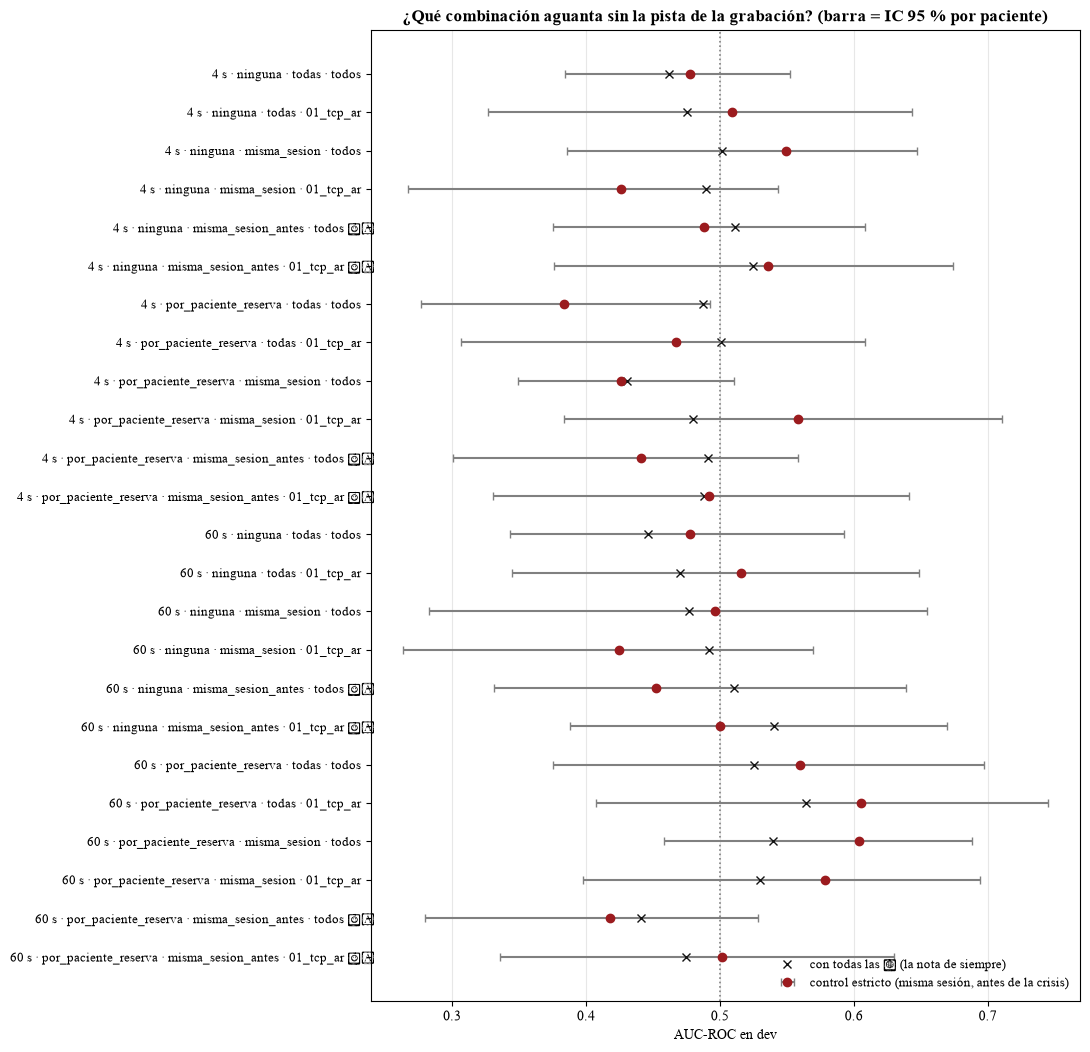

In [12]:
# 1) Figura: la AUC del control estricto de cada combinación, con su intervalo
r = resultados.reset_index()
etiquetas = [f'{c} · {n} · {mu} · {mo}' + ('' if e == 'sí' else ' ⚠️')
             for c, n, mu, mo, e in zip(r['contexto'], r['normalización'], r['muestreo'], r['montaje de entrenamiento'], r['elegible'])]
estricta = r[f'AUC · {CONTROL_ESTRICTO}'].to_numpy()
inferior = r[f'_inf · {CONTROL_ESTRICTO}'].to_numpy()
superior = r[f'_sup · {CONTROL_ESTRICTO}'].to_numpy()
todas_auc = r['AUC · todas las 💤'].to_numpy()

with plt.rc_context(ESTILO_TIMES):
    fig, ax = plt.subplots(figsize=(11, 0.38 * len(r) + 1.5))
    pos_y = np.arange(len(r))[::-1]
    ax.errorbar(estricta, pos_y, xerr=[estricta - inferior, superior - estricta], fmt='o', color=COLORES_ESQUEMA['rojo'], ecolor='gray',
                capsize=3, label='control estricto (misma sesión, antes de la crisis)')
    ax.plot(todas_auc, pos_y, 'x', color=COLORES_ESQUEMA['negro'], label='con todas las 💤 (la nota de siempre)')
    ax.axvline(0.5, color='gray', ls=':', lw=1.2)
    ax.set_yticks(pos_y, etiquetas, fontsize=9)
    ax.set_xlabel('AUC-ROC en dev')
    ax.set_title('¿Qué combinación aguanta sin la pista de la grabación? (barra = IC 95 % por paciente)', fontsize=12, fontweight='bold')
    ax.legend(frameon=False, loc='lower right', fontsize=9)
    ax.grid(alpha=0.3, axis='x')
    fig.tight_layout()
    fig.savefig(RUTA_FIGURAS / 'combinaciones_control_estricto.png', dpi=150, bbox_inches='tight')
    plt.show()

👀 **Cómo leer la figura.** Una fila por combinación (⚠️ = con muy pocas 💤 de entrenamiento: no puede ser la elegida). El punto rojo es la AUC con el control estricto (con su intervalo); la cruz negra, la AUC con todas las 💤. La línea de puntos es el azar.

✅ **Qué deberías ver:** si alguna barra roja queda **entera a la derecha de 0,5**, hay señal preictal que sobrevive sin la pista. Si la cruz negra está muy a la derecha del punto rojo, esa combinación se apoyaba en el atajo.

## 8. La decisión: qué recibe la red

> 🎯 **Qué hacemos:** elegir, entre las combinaciones **elegibles** (con al menos `MINIMO_INTERICTAL` 💤 de entrenamiento), la de mejor AUC en el **control estricto** y compararla, emparejada, con la línea base (4 s, sin normalizar, todas las 💤, todos los montajes) en ese mismo control.
>
> 🤔 **Las reglas, fijadas antes de mirar:**
> - **Hay señal** si el intervalo de la mejor en el control estricto queda **entero por encima de 0,5**.
> - **Se cambia** lo que recibe la red solo si la mejor mejora a la línea base en el control estricto de forma **real y suficiente** (intervalo de la diferencia por encima de 0 y al menos `MEJORA_MINIMA`); si no, la red recibe la línea base, como en F03.03.
> - El control estricto solo cuenta si tiene al menos `MINIMO_PACIENTES_CONTROL` pacientes con las dos clases.
>
> ⚠️ Elegir la mejor de 24 combinaciones con 🟡 dev la hace algo optimista: por eso la regla de "hay señal" pide el intervalo entero por encima del azar, no solo la cifra.

In [13]:
# 1) La mejor combinación ELEGIBLE en el control estricto y la línea base
fila_de = lambda k: (f'{k[0]} s', k[1], k[2], k[3])                              # de la clave de puntuaciones a la fila de la tabla
m_estricto = controles[CONTROL_ESTRICTO]
pacientes_estricto = len({p for p in set(pacientes[m_estricto]) if len(set(y[m_estricto & (pacientes == p)])) == 2})
control_fiable = pacientes_estricto >= MINIMO_PACIENTES_CONTROL
base = (min(CONTEXTOS), 'ninguna', 'todas', 'todos')
elegibles = [k for k in puntuaciones if resultados.loc[fila_de(k), 'elegible'] == 'sí']
mejor = max(elegibles, key=lambda k: resultados.loc[fila_de(k), f'AUC · {CONTROL_ESTRICTO}'])
fila_mejor = resultados.loc[fila_de(mejor)]
auc_estricta = auroc_con_intervalo(y[m_estricto], puntuaciones[mejor][m_estricto], pacientes[m_estricto], n_bootstrap=N_BOOTSTRAP, semilla=SEMILLA)
dif_base = diferencia_auroc_con_intervalo(y[m_estricto], puntuaciones[mejor][m_estricto], puntuaciones[base][m_estricto], pacientes[m_estricto],
                                          n_bootstrap=N_BOOTSTRAP, semilla=SEMILLA)

# 2) Las reglas
hay_senal = bool(control_fiable and auc_estricta[1] > 0.5)
mejora_clara = bool(control_fiable and dif_base[1] > 0 and dif_base[0] >= MEJORA_MINIMA and mejor != base)
elegida = mejor if mejora_clara else base
auc_elegida_todas = auroc_con_intervalo(y[validar], puntuaciones[elegida][validar], pacientes[validar], n_bootstrap=N_BOOTSTRAP, semilla=SEMILLA)
auc_elegida_estricta = auroc_con_intervalo(y[m_estricto], puntuaciones[elegida][m_estricto], pacientes[m_estricto], n_bootstrap=N_BOOTSTRAP, semilla=SEMILLA)
senal_con_todas = bool(any(resultados.loc[fila_de(k), '_inf · todas las 💤'] > 0.5 for k in elegibles))

# 3) El veredicto
describir = lambda k: f'{k[0]} s · {k[1]} · muestreo {k[2]} · montaje {k[3]}'
texto_mejor = describir(mejor)
if not control_fiable:
    veredicto = ('🟡 No se puede decidir: el control estricto tiene pocos pacientes',
                 f'Solo {pacientes_estricto} pacientes de dev tienen ⏳ y 💤 de antes de la crisis en la misma sesión (mínimo {MINIMO_PACIENTES_CONTROL}). '
                 'La red recibe la línea base y hay que buscar otra forma de medir (por ejemplo, validación cruzada con train + dev).')
elif hay_senal and mejora_clara:
    veredicto = ('✅ Hay señal preictal sin la pista, y el arreglo ayuda',
                 f'La mejor combinación ({texto_mejor}) da <b>AUC {con_intervalo(*auc_estricta)}</b> en el control estricto, '
                 f'{con_signo(dif_base[0])} sobre la línea base (IC {decimal(dif_base[1], 3)} – {decimal(dif_base[2], 3)}). '
                 'La red la recibe y merece la pena reentrenar F03.04-F03.08 con ella.')
elif hay_senal:
    veredicto = ('🟡 Hay señal sin la pista, pero los arreglos no la mejoran con claridad',
                 f'La mejor combinación ({texto_mejor}) da AUC {con_intervalo(*auc_estricta)} en el control estricto, pero frente a la línea base '
                 f'la diferencia es {con_signo(dif_base[0])} (IC {decimal(dif_base[1], 3)} – {decimal(dif_base[2], 3)}). La red recibe la línea base; '
                 'medir siempre las redes con el control estricto.')
elif senal_con_todas:
    veredicto = ('🔴 Sin la pista de la grabación no queda señal preictal',
                 f'Con todas las 💤 alguna combinación supera el azar, pero con el control estricto ninguna (la mejor, {texto_mejor}: '
                 f'AUC {con_intervalo(*auc_estricta)}). Lo que separaba ⏳ de 💤 era la grabación, no la cercanía de la crisis. '
                 'Antes de reentrenar redes, valorar: predicción por paciente, otro dataset con registros largos, o cerrar la fase con este resultado.')
else:
    veredicto = ('🔴 No hay señal preictal, ni con la pista ni sin ella',
                 f'Ninguna combinación supera el azar, ni con todas las 💤 ni con el control estricto (la mejor en el estricto, {texto_mejor}: '
                 f'AUC {con_intervalo(*auc_estricta)}). Con estos datos y este planteamiento (entre pacientes, ventana a ventana) los modelos '
                 'no separan ⏳ de 💤. Antes de reentrenar redes, ' + ('revisar el diagnóstico 3 (el montaje) y ' if veredicto_montaje[0].startswith('🔴') else '') + 'valorar: predicción '
                 'por paciente, otro dataset con registros largos, o cerrar la fase con este resultado.')

# 4) Mostrarlo destacado
decision = pd.DataFrame([
    (f'línea base ({describir(base)})', decimal(resultados.loc[fila_de(base), 'AUC · todas las 💤']),
     decimal(resultados.loc[fila_de(base), f'AUC · {CONTROL_ESTRICTO}'])),
    (f'mejor en el control estricto ({texto_mejor})', decimal(fila_mejor['AUC · todas las 💤']), con_intervalo(*auc_estricta)),
    (f'👉 lo que recibe la red ({describir(elegida)})', con_intervalo(*auc_elegida_todas), con_intervalo(*auc_elegida_estricta)),
], columns=['combinación', 'AUC con todas las 💤', 'AUC en el control estricto']).set_index('combinación')
mostrar_destacado(f'Decisión para la red · {veredicto[0]}', veredicto[1], decision,
                  f'Control estricto: {pacientes_estricto} pacientes con las dos clases · {len(elegibles)} de {len(puntuaciones)} combinaciones elegibles · '
                  f'diagnóstico 1: {veredicto_atajo[0]} · diagnóstico 3: {veredicto_montaje[0]}.')

,AUC con todas las 💤,AUC en el control estricto
combinación,,
línea base (4 s · ninguna · muestreo todas · montaje todos),"0,46","0,48"
mejor en el control estricto (60 s · por_paciente_reserva · muestreo todas · montaje 01_tcp_ar),"0,56","0,61 [0,41 – 0,74]"
👉 lo que recibe la red (4 s · ninguna · muestreo todas · montaje todos),"0,46 [0,42 – 0,52]","0,48 [0,38 – 0,55]"


👀 **Cómo leer el recuadro.** Arriba, el veredicto con las reglas de la celda anterior. La tabla compara la línea base, la mejor combinación en el control estricto y lo que recibe la red, con las dos notas: la de siempre y la estricta.

✅ **Qué deberías ver:** uno de tres casos.
- ✅ **Hay señal y el arreglo ayuda:** F03.04 leerá esta decisión sola; reentrena F03.04-F03.08.
- 🟡 **Hay señal, pero sin mejora clara:** la red recibe la línea base; lo importante es medirla siempre con el control estricto (F03.04 ya lo hace).
- 🔴 **No queda señal** (sin la pista, o ni siquiera con ella): es un resultado, no un fallo. Antes de gastar horas de GPU, decidir el siguiente paso (§11).

## 9. El resultado → tablas, puntuaciones y `configuracion.json`

> 🎯 **Qué hacemos:** guardarlo todo. `configuracion.json` lleva la **decisión para la red**: F03.04 y `tfm_comun/red/preparacion.py` la leen solos (`tfm_comun/prediccion/atajo_grabacion.py: leer_decision_red`).

In [14]:
# 1) Tablas
resultados[columnas_ver].reset_index().to_csv(RUTA_RESULTADOS / 'resultados_combinaciones.csv', index=False)
mostrar_fichero(RUTA_RESULTADOS / 'resultados_combinaciones.csv', 'una fila por contexto × normalización × muestreo: AUC en dev con todas las 💤, misma sesión y control estricto')
diagnostico_postictal.reset_index().to_csv(RUTA_RESULTADOS / 'diagnostico_postictal.csv', index=False)
mostrar_fichero(RUTA_RESULTADOS / 'diagnostico_postictal.csv', 'los modelos ya entrenados (F03.03, F03.04) en cada control, con las 💤 de antes y después de una crisis separadas')
tabla_montaje.reset_index().to_csv(RUTA_RESULTADOS / 'montaje_por_tipo_de_sesion.csv', index=False)
firma.reset_index().to_csv(RUTA_RESULTADOS / 'montaje_canales_vacios.csv', index=False)
auc_por_montaje.reset_index().to_csv(RUTA_RESULTADOS / 'auc_por_montaje.csv', index=False)
mostrar_fichero(RUTA_RESULTADOS / 'montaje_canales_vacios.csv', 'canales vacíos por partición, montaje original y clase (§6b)')

# 2) Puntuaciones de dev (mismas columnas que F03.03: F03.04 las compara con la red)
puntos = filas.loc[validar, ['id_ventana', 'split', 'patient', 'file', 'clase', 'etiqueta', 'grupo', 'crisis_id']].copy()
puntos['antes_de_toda_crisis'] = antes[validar]
puntos['puntuacion_linea_base_4s'] = puntuaciones[base][validar].round(5)
puntos['puntuacion_mejor'] = puntuaciones[elegida][validar].round(5)
puntos.to_csv(RUTA_RESULTADOS / 'puntuaciones_validacion.csv', index=False)
mostrar_fichero(RUTA_RESULTADOS / 'puntuaciones_validacion.csv', 'una fila por ventana de dev: la línea base y lo que recibe la red (XGBoost), y si la 💤 es de antes de toda crisis')

# 3) configuracion.json: la decisión para la red (mismas claves que F03.03 donde coinciden)
config = {
    'conjunto': CONJUNTO, 'splits_usados': SPLITS, 'eval_usado': False, 'contextos_s': config_03['contextos_s'],
    'contextos_probados_s': CONTEXTOS, 'normalizaciones': NORMALIZACIONES, 'muestreos': LISTA_MUESTREOS,
    'modelos': {MODELO: {'variante': VARIANTE, 'hiperparametros': HIPERPARAMETROS}},
    'ventanas_estudiadas': int(len(filas)), 'reserva_calibracion': {**RESERVA, 'por_sesion': False}, 'montajes': LISTA_MONTAJES, 'minimo_interictal': MINIMO_INTERICTAL,
    'diagnostico_sesion': {'veredicto': veredicto_atajo[0], 'auc_dev': float(auc_s[0]), 'ic95_dev': [float(auc_s[1]), float(auc_s[2])],
                           'auc_dentro_paciente': float(auc_s_dentro[0]), 'pacientes_dentro': len(pac_dos)},
    'control_estricto': {'nombre': CONTROL_ESTRICTO, 'pacientes_con_las_dos_clases': pacientes_estricto, 'fiable': bool(control_fiable)},
    'diagnostico_montaje': {'veredicto': veredicto_montaje[0], 'pct_ventanas_con_canal_vacio': {k: float(v) for k, v in por_montaje.items()}},
    'mejor': {'modelo': MODELO, 'contexto_s': int(elegida[0]), 'normalizacion': elegida[1], 'muestreo': elegida[2], 'montaje_entrenamiento': elegida[3],
              'auc_dev': float(auc_elegida_todas[0]), 'ic95_dev': [float(auc_elegida_todas[1]), float(auc_elegida_todas[2])],
              'auc_estricta': float(auc_elegida_estricta[0]), 'ic95_estricta': [float(auc_elegida_estricta[1]), float(auc_elegida_estricta[2])]},
    'mejor_en_control_estricto': {'contexto_s': int(mejor[0]), 'normalizacion': mejor[1], 'muestreo': mejor[2], 'montaje_entrenamiento': mejor[3],
                                  'auc_estricta': float(auc_estricta[0]), 'ic95_estricta': [float(auc_estricta[1]), float(auc_estricta[2])],
                                  'diferencia_con_base': float(dif_base[0]), 'ic95_diferencia': [float(dif_base[1]), float(dif_base[2])]},
    'decision_red': {'contexto_s': int(elegida[0]), 'normalizacion': elegida[1], 'muestreo': elegida[2], 'montaje_entrenamiento': elegida[3],
                     'hay_senal': hay_senal, 'mejora_clara': mejora_clara, 'texto': veredicto[0]},
    'mejora_minima': MEJORA_MINIMA, 'semilla': SEMILLA, 'versiones': versiones_usadas, 'fecha': time.strftime('%Y-%m-%d %H:%M'),
}
(RUTA_RESULTADOS / 'configuracion.json').write_text(json.dumps(config, ensure_ascii=False, indent=4), encoding='utf-8')
mostrar_fichero(RUTA_RESULTADOS / 'configuracion.json', 'la decisión para la red (contexto, normalización y muestreo) y su respaldo: F03.04 y preparacion.py la leen solos')

💾 **Guardado `resultados_combinaciones.csv`** · 4,4 KB · 24 filas × 13 columnas  
*Qué guarda:* una fila por contexto × normalización × muestreo: AUC en dev con todas las 💤, misma sesión y control estricto. *Abajo:* las 5 primeras filas.

,contexto,normalización,muestreo,montaje de entrenamiento,⏳ de entrenamiento,💤 de entrenamiento,elegible,AUC · todas las 💤,IC · todas las 💤,AUC · misma sesión,IC · misma sesión,"AUC · misma sesión, antes de la crisis","IC · misma sesión, antes de la crisis"
0,4 s,ninguna,todas,todos,13329,10039,sí,0.461937,"0,42 – 0,52",0.454665,"0,40 – 0,52",0.477395,"0,38 – 0,55"
1,4 s,ninguna,todas,01_tcp_ar,7518,5929,sí,0.475113,"0,41 – 0,53",0.482002,"0,40 – 0,54",0.509172,"0,33 – 0,64"
2,4 s,ninguna,misma_sesion,todos,13329,5308,sí,0.501275,"0,45 – 0,55",0.510786,"0,44 – 0,56",0.549693,"0,39 – 0,65"
3,4 s,ninguna,misma_sesion,01_tcp_ar,7518,2018,sí,0.489494,"0,45 – 0,54",0.500204,"0,43 – 0,56",0.426134,"0,27 – 0,54"
4,4 s,ninguna,misma_sesion_antes,todos,13329,443,⚠️ no (menos de 2.000 💤),0.511105,"0,45 – 0,58",0.483826,"0,42 – 0,58",0.487940,"0,38 – 0,61"


💾 **Guardado `diagnostico_postictal.csv`** · 658 B · 5 filas × 6 columnas  
*Qué guarda:* los modelos ya entrenados (F03.03, F03.04) en cada control, con las 💤 de antes y después de una crisis separadas. *Abajo:* las 5 primeras filas.

,qué 💤 se usan,pacientes con las dos clases,💤 interictal,F03.03 · línea base (4 s),"F03.03 · mejor (60 s, por_paciente)",F03.04 · red_4s
0,todas las 💤,28,41310,"0,46 [0,38 – 0,53]","0,58 [0,50 – 0,63]","0,43 [0,36 – 0,54]"
1,misma sesión,25,7312,"0,45 [0,37 – 0,55]","0,54 [0,46 – 0,59]","0,36 [0,30 – 0,48]"
2,"misma sesión, antes de la crisis",15,1609,"0,47 [0,35 – 0,59]","0,51 [0,38 – 0,62]","0,30 [0,22 – 0,46]"
3,"misma sesión, después de una crisis",23,5703,"0,45 [0,36 – 0,55]","0,54 [0,47 – 0,59]","0,38 [0,31 – 0,50]"
4,mismo fichero,18,1020,"0,37 [0,28 – 0,48]","0,43 [0,30 – 0,55]","0,30 [0,23 – 0,41]"


💾 **Guardado `montaje_canales_vacios.csv`** · 678 B · 12 filas × 6 columnas  
*Qué guarda:* canales vacíos por partición, montaje original y clase (§6b). *Abajo:* las 5 primeras filas.

,split,montaje,clase,ventanas,% con algún canal vacío,canales vacíos (media)
0,🔵 train,01_tcp_ar,⏳ preictal,7518,0.0,0.0
1,🔵 train,01_tcp_ar,💤 interictal,5929,0.0,0.0
2,🔵 train,02_tcp_le,⏳ preictal,1739,0.0,0.0
3,🔵 train,02_tcp_le,💤 interictal,1119,0.0,0.0
4,🔵 train,03_tcp_ar_a,⏳ preictal,4072,100.0,2.0


💾 **Guardado `puntuaciones_validacion.csv`** · 6 MB · 48.829 filas × 11 columnas  
*Qué guarda:* una fila por ventana de dev: la línea base y lo que recibe la red (XGBoost), y si la 💤 es de antes de toda crisis. *Abajo:* las 5 primeras filas.

,id_ventana,split,patient,file,clase,etiqueta,grupo,crisis_id,antes_de_toda_crisis,puntuacion_linea_base_4s,puntuacion_mejor
0,aaaaaayf_s001_t001_interictal_000000000_000028672,🟡 dev,aaaaaayf,aaaaaayf_s001_t001,💤 interictal,0,nan,NaN,True,0.84091,0.84091
1,aaaaaayf_s001_t001_interictal_000000000_000029696,🟡 dev,aaaaaayf,aaaaaayf_s001_t001,💤 interictal,0,nan,NaN,True,0.77278,0.77278
2,aaaaaayf_s001_t001_interictal_000000000_000030720,🟡 dev,aaaaaayf,aaaaaayf_s001_t001,💤 interictal,0,nan,NaN,True,0.43471,0.43471
3,aaaaaayf_s001_t001_interictal_000000000_000031744,🟡 dev,aaaaaayf,aaaaaayf_s001_t001,💤 interictal,0,nan,NaN,True,0.82315,0.82315
4,aaaaaayf_s001_t001_interictal_000000000_000032768,🟡 dev,aaaaaayf,aaaaaayf_s001_t001,💤 interictal,0,nan,NaN,True,0.61036,0.61036


💾 **Guardado `configuracion.json`** · 3,5 KB · 22 claves  
*Qué guarda:* la decisión para la red (contexto, normalización y muestreo) y su respaldo: F03.04 y preparacion.py la leen solos. *Abajo:* todas las claves (son pocas).

,valor
clave,
conjunto,general
splits_usados,"[""train"", ""dev""]"
eval_usado,false
contextos_s,"[4, 8, 16, 32, 60]"
contextos_probados_s,"[4, 60]"
normalizaciones,"[""ninguna"", ""por_paciente_reserva""]"
muestreos,"[""todas"", ""misma_sesion"", ""misma_sesion_antes""]"
modelos,"{""xgboost"": {""variante"": ""mismo_peso_paciente"", ""hiperparametros"": {""max_depth"": 5, ""n_est…"
ventanas_estudiadas,72197


## 10. Resumen → `summary.txt` y conclusiones

> 🎯 **Qué hacemos:** guardar las cifras clave y escribir las conclusiones con los datos de esta ejecución.

In [15]:
# 1) summary.txt
lineas = [
    f'F03.03b · El atajo de la grabación: {config["fecha"]} · conjunto {CONJUNTO} · semilla {SEMILLA} · 🟢 eval no usado',
    f'{numero_legible(len(filas))} ventanas (sin reservas de calibración por paciente ni por sesión)',
    f'Diagnóstico 1 (¿se reconoce la sesión solo con 💤?): {veredicto_atajo[0]} · AUC {con_intervalo(*auc_s)}',
    f'Control estricto ({CONTROL_ESTRICTO}): {pacientes_estricto} pacientes con las dos clases' + ('' if control_fiable else ' (pocos: no fiable)'),
    f'Mejor en el control estricto: {texto_mejor} → AUC {con_intervalo(*auc_estricta)} ({con_signo(dif_base[0])} sobre la línea base; '
    f'IC {decimal(dif_base[1], 3)} – {decimal(dif_base[2], 3)})',
    f'Diagnóstico 3 (montaje): {veredicto_montaje[0]}',
    f'Decisión para la red: {veredicto[0]} → {describir(elegida)}',
]
texto = ('=== F03.03b · El atajo de la grabación ===\n' + '\n'.join(lineas) + '\n\n--- Combinaciones ---\n'
         + resultados[columnas_ver].round(3).to_string() + '\n\n--- Diagnóstico postictal (modelos ya entrenados) ---\n' + diagnostico_postictal.to_string()
         + '\n\n--- Diagnóstico del montaje: canales vacíos ---\n' + firma.round(1).to_string()
         + '\n\n--- AUC dentro de cada montaje (modelos ya entrenados) ---\n' + auc_por_montaje.to_string() + '\n')
(RUTA_RESULTADOS / 'summary.txt').write_text(texto, encoding='utf-8')
mostrar_fichero(RUTA_RESULTADOS / 'summary.txt', 'el resumen en texto')

# 2) Conclusiones, escritas solas
fila_base = resultados.loc[fila_de(base)]
caida_base = fila_base['AUC · todas las 💤'] - fila_base[f'AUC · {CONTROL_ESTRICTO}']
conclusiones = [
    f'**1. El atajo.** {veredicto_atajo[0]}. ' + re.sub('<[^>]+>', '', veredicto_atajo[1]),
    f'**2. La línea base sin la pista.** Con todas las 💤 saca {decimal(fila_base["AUC · todas las 💤"])}; con el control estricto, '
    f'{decimal(fila_base[f"AUC · {CONTROL_ESTRICTO}"])} ({con_signo(-caida_base)}): '
    + ('casi toda su nota venía de la pista.' if caida_base > 0.05 and fila_base['_inf · todas las 💤'] > 0.5 else
       'ya estaba en el azar con todas las 💤: no había nada que la pista inflara.' if fila_base['_inf · todas las 💤'] <= 0.5 else
       'la pista apenas le aportaba.'),
    f'**3. Los arreglos.** La mejor combinación en el control estricto es {texto_mejor}: AUC {con_intervalo(*auc_estricta)}, '
    f'{con_signo(dif_base[0])} sobre la línea base (IC {decimal(dif_base[1], 3)} – {decimal(dif_base[2], 3)}): {lectura_diferencia(dif_base, MEJORA_MINIMA)}.',
    f'**4. El montaje: {veredicto_montaje[0]}.** ' + re.sub('<[^>]+>', '', veredicto_montaje[1]),
    f'**5. Decisión para la red: {veredicto[0]}.** ' + re.sub('<[^>]+>', '', veredicto[1]),
    '**6. Para la memoria:** el atajo de la grabación es un problema conocido de los datos de EEG clínicos (las ⏳ salen de sesiones distintas a las 💤). '
    'Aquí se mide, se busca su causa (sesión o postictal) y se elimina antes de comparar redes; la nota que cuenta es la del control estricto.',
]
display(Markdown('\n\n'.join(conclusiones)))

💾 **Guardado `summary.txt`** · 12,1 KB · 68 líneas  
*Qué guarda:* el resumen en texto. *Abajo:* las 5 primeras líneas con texto.

,texto
línea,
1,=== F03.03b · El atajo de la grabación ===
2,F03.03b · El atajo de la grabación: 2026-11-19 16:03 · conjunto general · semilla 42 · 🟢 eval no usado
3,72.197 ventanas (sin reservas de calibración por paciente ni por sesión)
4,"Diagnóstico 1 (¿se reconoce la sesión solo con 💤?): ✅ La sesión no se reconoce solo con 💤 · AUC 0,47 [0,39 – 0,55]"
5,"Control estricto (misma sesión, antes de la crisis): 15 pacientes con las dos clases"


**1. El atajo.** ✅ La sesión no se reconoce solo con 💤. AUC 0,47 [0,39 – 0,55]: con estas características la grabación no se delata por sí sola. Si el control de sesión cae, la causa más probable es el postictal (§6).

**2. La línea base sin la pista.** Con todas las 💤 saca 0,46; con el control estricto, 0,48 (+0,015): ya estaba en el azar con todas las 💤: no había nada que la pista inflara.

**3. Los arreglos.** La mejor combinación en el control estricto es 60 s · por_paciente_reserva · muestreo todas · montaje 01_tcp_ar: AUC 0,61 [0,41 – 0,74], +0,128 sobre la línea base (IC -0,064 – 0,300): sin diferencia clara (el intervalo incluye el 0).

**4. El montaje: 🟢 El montaje se reconoce, pero no va con la clase.** Las ventanas de 03_tcp_ar_a tienen canales vacíos, así que un modelo puede reconocer ese montaje, pero hay casi la misma proporción en ⏳ que en 💤 (🟡 dev: 14 % de las ⏳ y 16 % de las 💤; 🔵 train: 31 % de las ⏳ y 30 % de las 💤): no le sirve para separarlas. Coincide con F02.05 (canales_a_cero no separa). No hace falta tocar la Fase 2.

**5. Decisión para la red: 🔴 No hay señal preictal, ni con la pista ni sin ella.** Ninguna combinación supera el azar, ni con todas las 💤 ni con el control estricto (la mejor en el estricto, 60 s · por_paciente_reserva · muestreo todas · montaje 01_tcp_ar: AUC 0,61 [0,41 – 0,74]). Con estos datos y este planteamiento (entre pacientes, ventana a ventana) los modelos no separan ⏳ de 💤. Antes de reentrenar redes, valorar: predicción por paciente, otro dataset con registros largos, o cerrar la fase con este resultado.

**6. Para la memoria:** el atajo de la grabación es un problema conocido de los datos de EEG clínicos (las ⏳ salen de sesiones distintas a las 💤). Aquí se mide, se busca su causa (sesión o postictal) y se elimina antes de comparar redes; la nota que cuenta es la del control estricto.

## 11. Cómo sigue

- **F03.04 lee esta decisión sola** (`leer_decision_red`): mismas ventanas (las de F03.03), la normalización elegida, el **muestreo** y el **montaje** de entrenamiento, y la comparación con el XGBoost de aquí. Su veredicto final usa el **control estricto**.
- **Si el diagnóstico 3 sale 🔴 (el montaje va con la clase):** quitar `A1-T3` y `T4-A2` a todos los montajes en las características de la Fase 3, o descartar los ficheros `03_tcp_ar_a` en la Fase 2, y volver a ejecutar desde ahí. Si sale 🟢, el montaje se reconoce pero no ayuda a separar ⏳ de 💤: no hay que hacer nada.
- **F03.05-F03.08** la heredan por `tfm_comun/red/preparacion.py`. Hay que **reejecutarlos**: sus resultados guardados son de antes de quitar la calibración con fuga.
- **Si el veredicto es 🔴**, antes de reentrenar redes, revisar el montaje (punto anterior) y valorar con el tutor:
  1. **predicción por paciente** (entrenar y medir dentro de cada paciente con varias crisis);
  2. **otro dataset** con registros continuos largos, reutilizando el código de la fase;
  3. **cerrar la Fase 3 con este resultado** (medido y explicado) y apoyar el TFM en la Fase 4 (clasificación de tipos).

> 📝 **Para la memoria.** Este notebook es el que permite defender cualquier cifra de predicción: muestra que la nota no viene de reconocer la grabación ni del postictal.

## 12. Archivos generados

En `outputs/fase_03/<conjunto>/03b_atajo_grabacion/`:

- `resultados_combinaciones.csv`: cada combinación con su AUC en los tres controles.
- `diagnostico_postictal.csv`: los modelos de F03.03 y F03.04 con las 💤 de antes y después de una crisis.
- `montaje_por_tipo_de_sesion.csv`: el montaje original según el tipo de ventana.
- `montaje_canales_vacios.csv` y `auc_por_montaje.csv`: el diagnóstico del montaje (§6b).
- `puntuaciones_validacion.csv`: la línea base y lo que recibe la red, ventana a ventana (para F03.04).
- `configuracion.json` (la decisión para la red) y `summary.txt`.
- `figuras/combinaciones_control_estricto.png`.